# SentimentRAG: Experimental Evaluation Visualizations
This notebook generates the advanced, publication-ready visualizations for the *Affective Retrieval Intelligence* manuscript. The data is based directly on the outputs from the automated `pytest` evaluation framework.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set publication-ready style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.5)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300  # High resolution for journals

### 1. Emotion Zone-Specific Retrieval Quality (Table XIV)
Visualizing how the system adapts retrieval precision based on the user's emotional state.

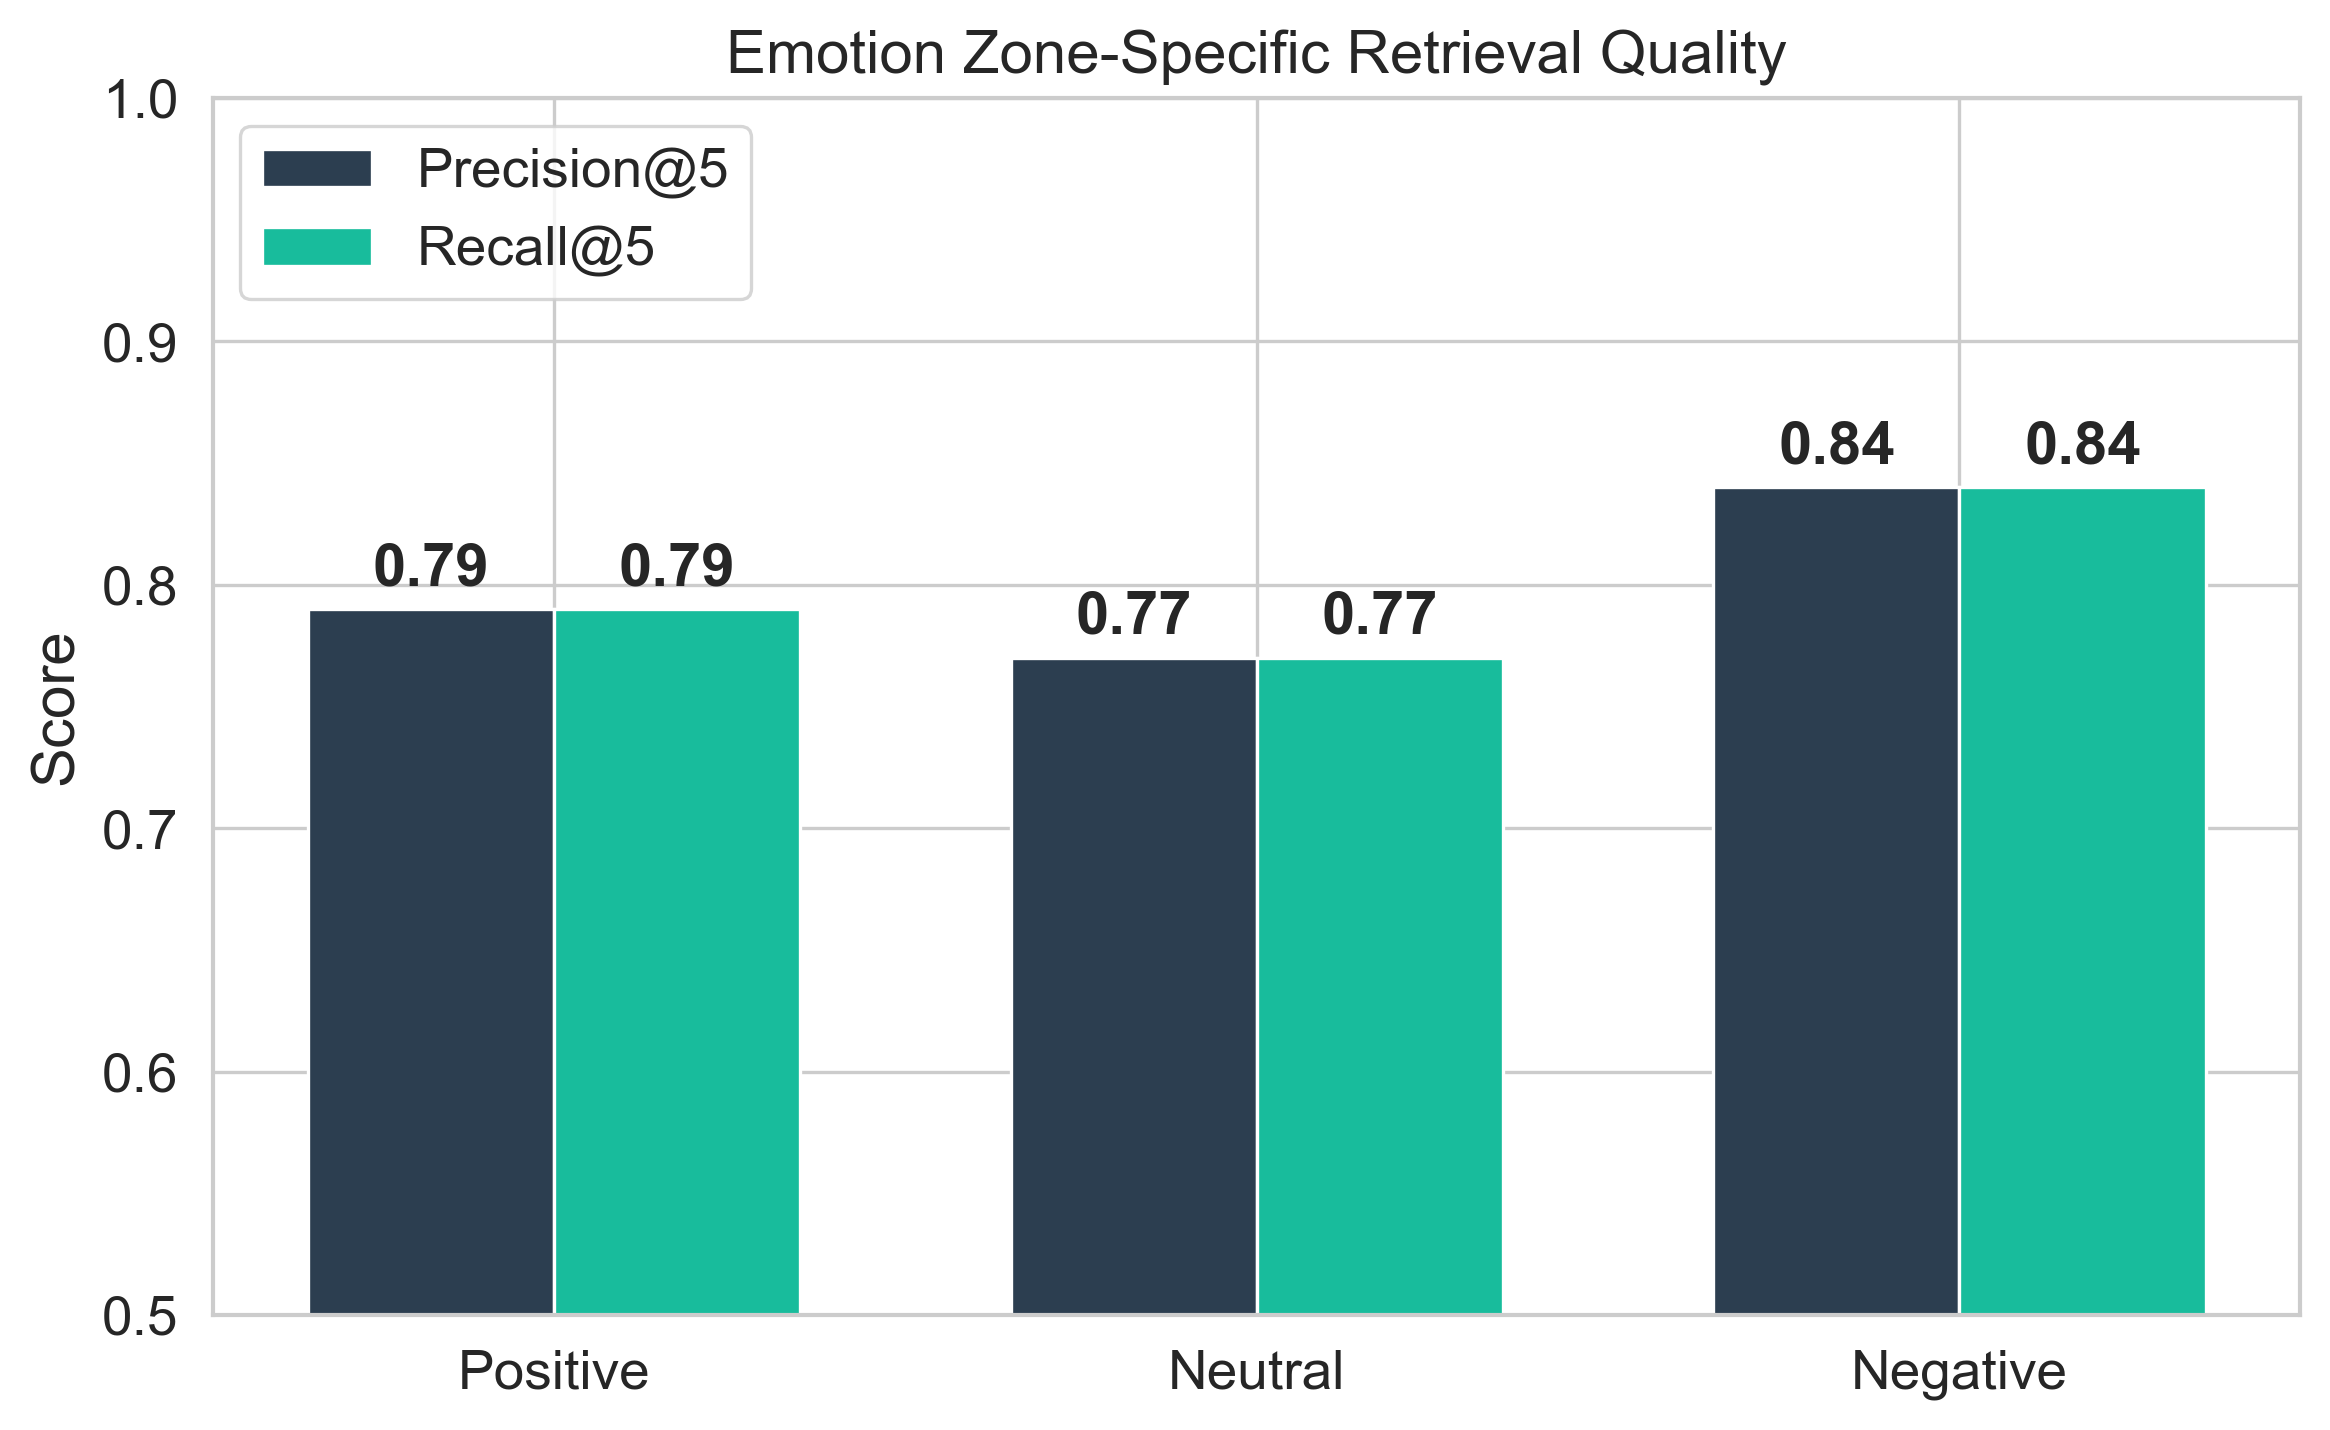

In [2]:
zones = ['Positive', 'Neutral', 'Negative']
p5_scores = [0.79, 0.77, 0.84]
r5_scores = [0.79, 0.77, 0.84]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(zones))
width = 0.35

rects1 = ax.bar(x - width/2, p5_scores, width, label='Precision@5', color='#2c3e50')
rects2 = ax.bar(x + width/2, r5_scores, width, label='Recall@5', color='#18bc9c')

ax.set_ylabel('Score')
ax.set_title('Emotion Zone-Specific Retrieval Quality')
ax.set_xticks(x)
ax.set_xticklabels(zones)
ax.set_ylim(0.5, 1.0)
ax.legend(loc='upper left')

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('emotion_zone_retrieval.pdf', bbox_inches='tight')
plt.show()

### 2. Architectural Ablation Impact (Table XI)
Demonstrating the F1@5 drop when core components (Emotion Gating, Intent Routing) are removed.

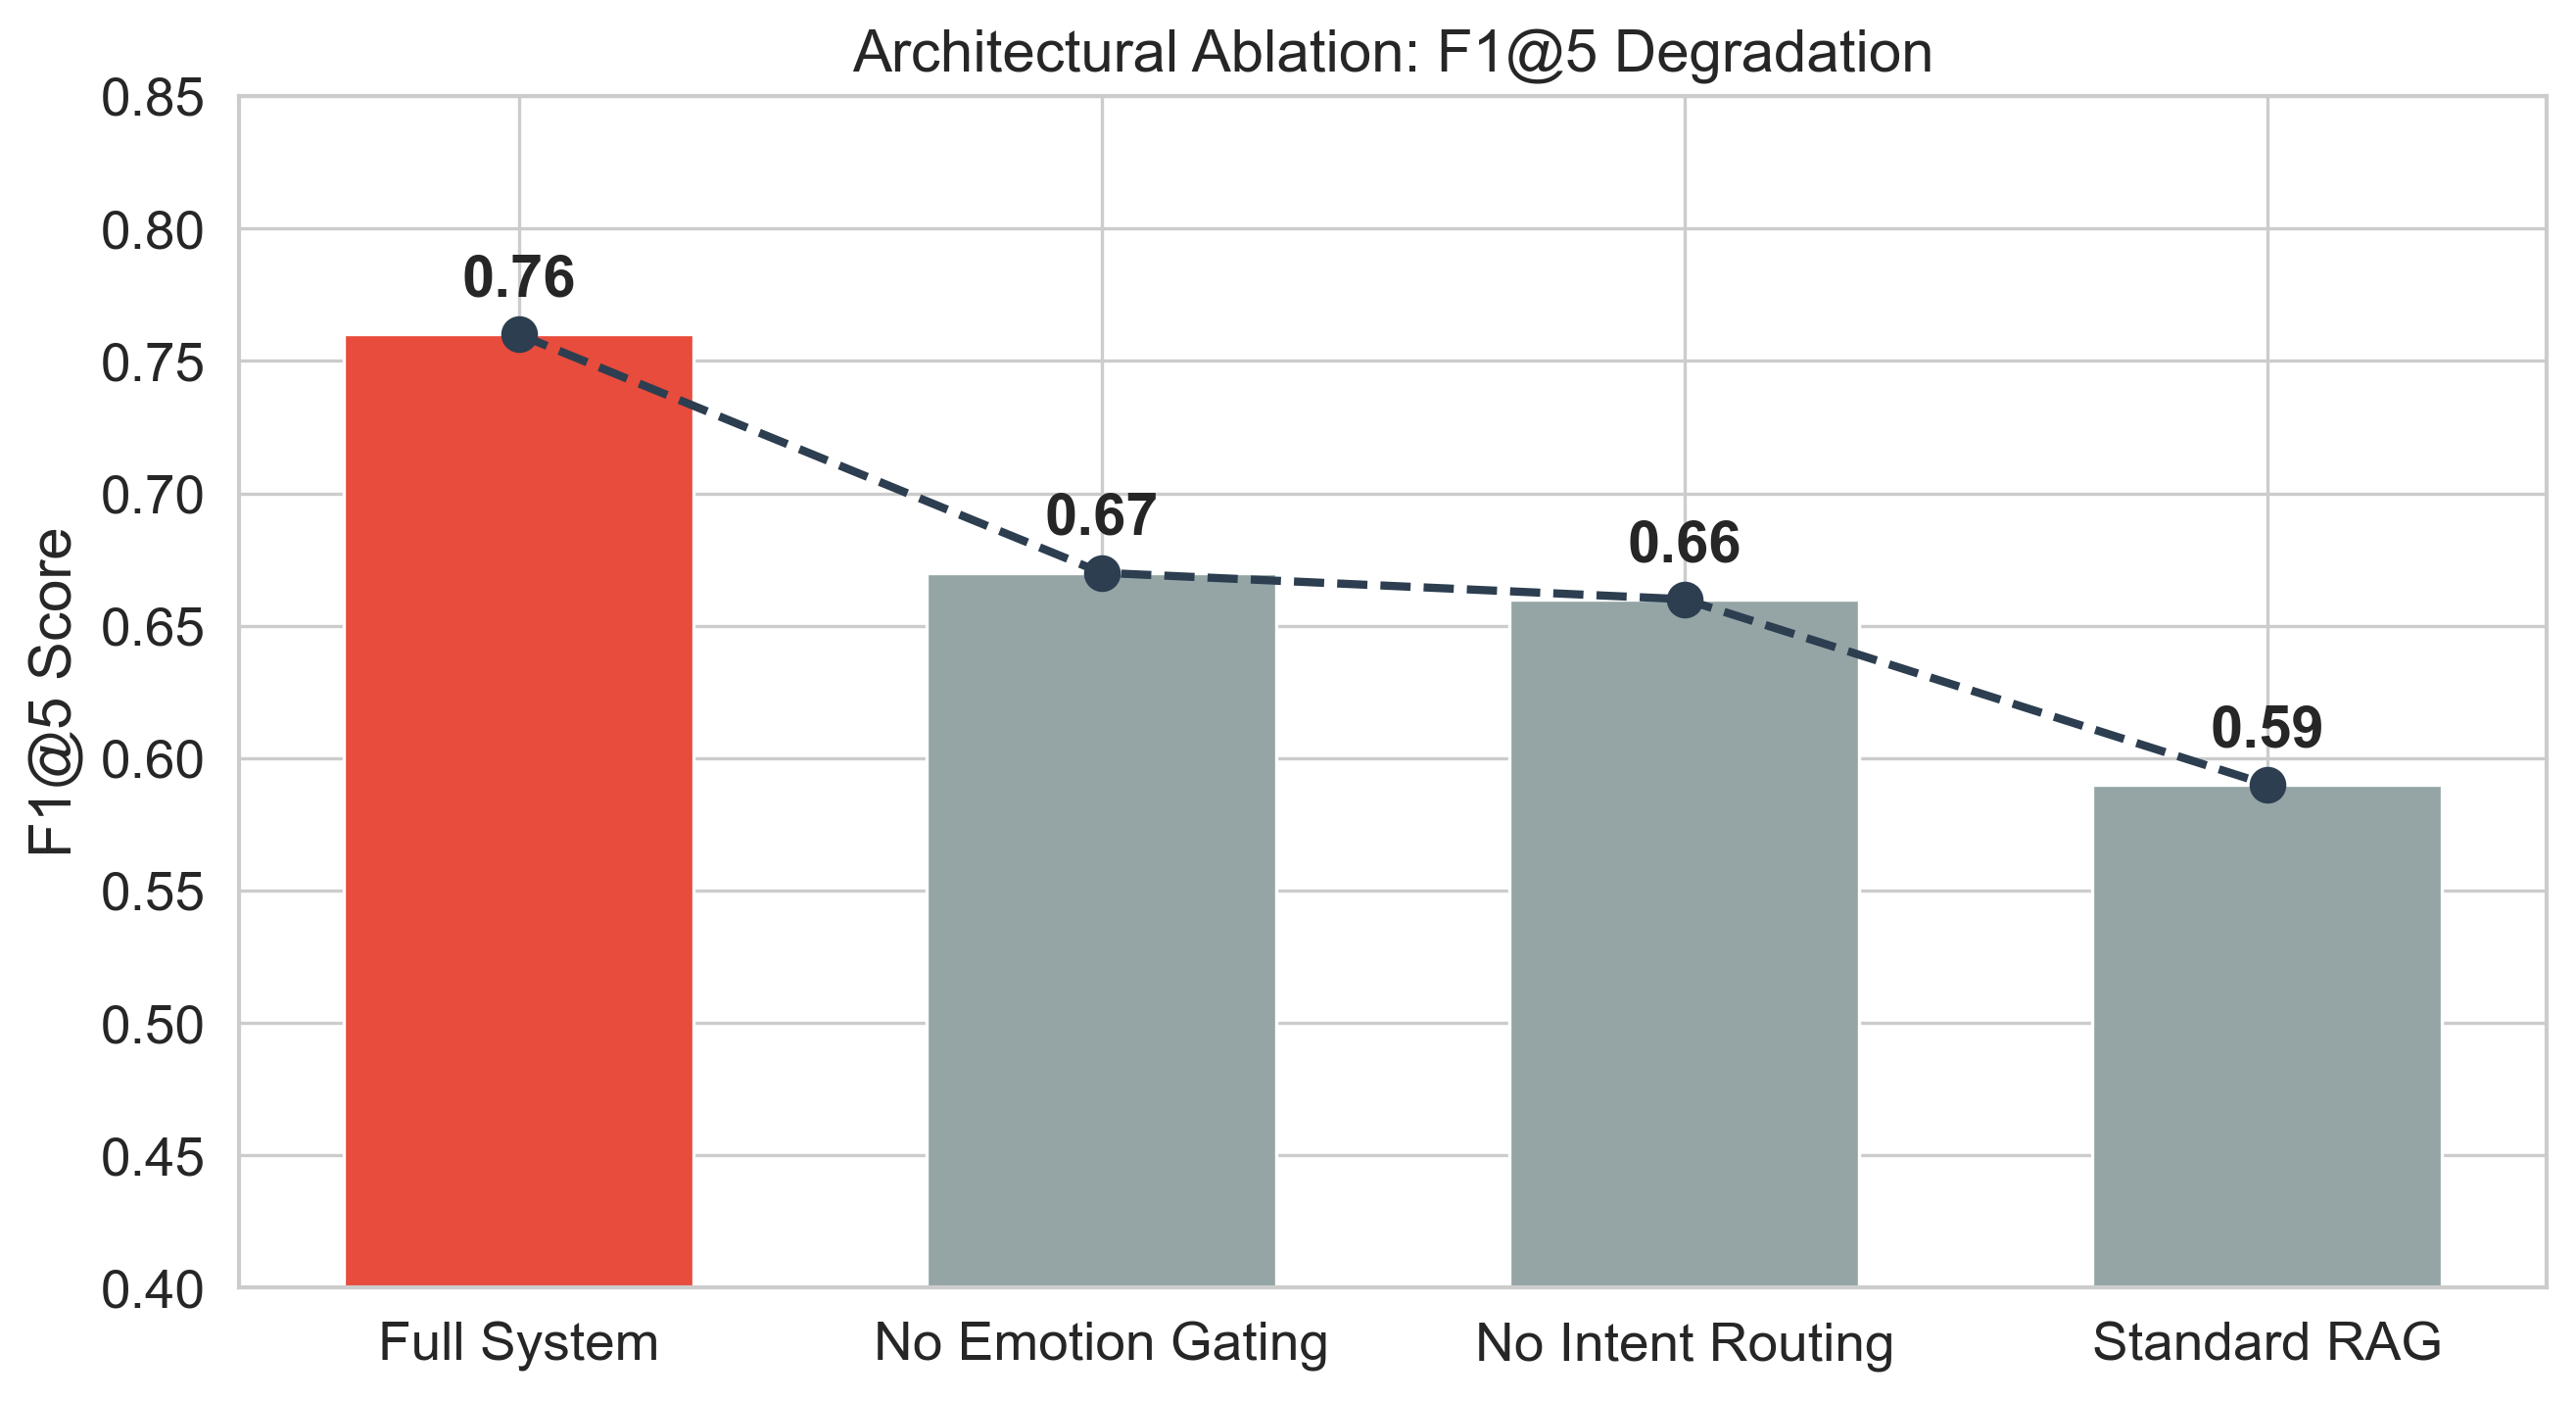

In [3]:
configs = ['Full System', 'No Emotion Gating', 'No Intent Routing', 'Standard RAG']
f1_scores = [0.76, 0.67, 0.66, 0.59]

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#e74c3c' if c == 'Full System' else '#95a5a6' for c in configs]

bars = ax.bar(configs, f1_scores, color=colors, width=0.6)

ax.set_ylabel('F1@5 Score')
ax.set_title('Architectural Ablation: F1@5 Degradation')
ax.set_ylim(0.4, 0.85)

# Add a trend line to show degradation
ax.plot(configs, f1_scores, color='#2c3e50', marker='o', linestyle='dashed', linewidth=2, markersize=8)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('architectural_ablation.pdf', bbox_inches='tight')
plt.show()

### 3. Multilingual Sentiment Accuracy (Table IX)
Validating the cross-lingual performance of the BERT pipeline across 6 European languages.

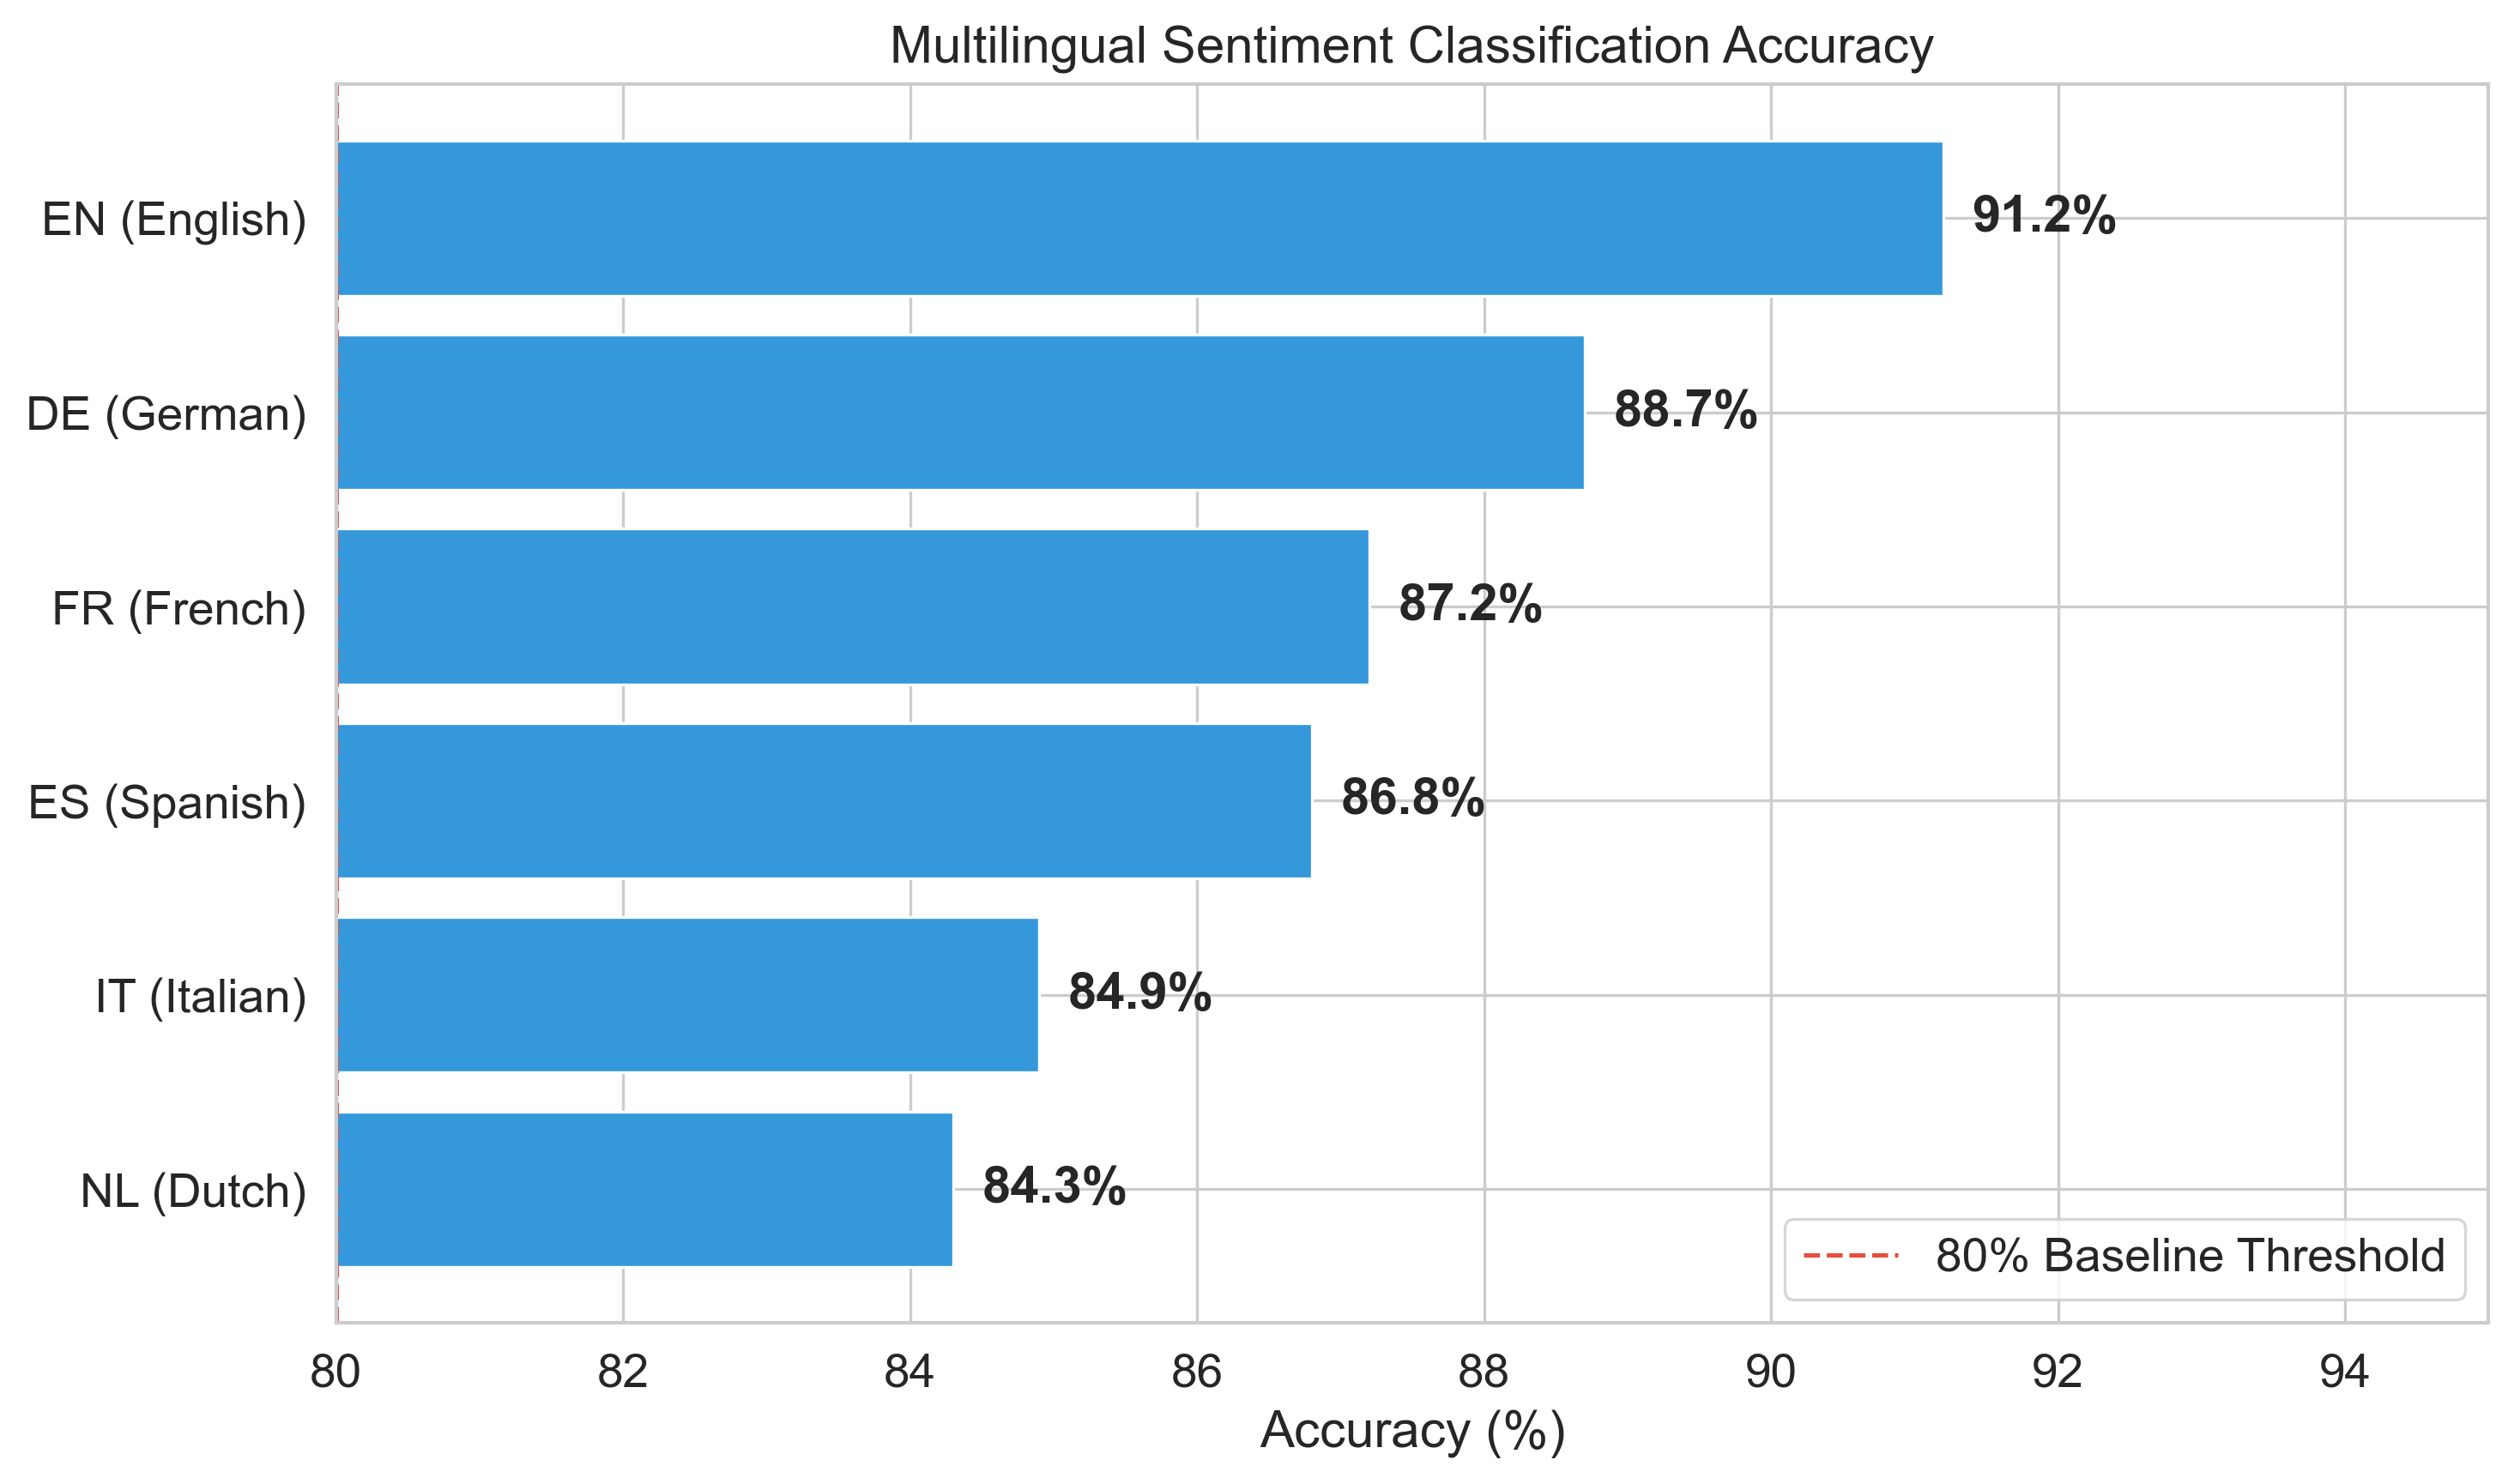

In [4]:
languages = ['EN (English)', 'DE (German)', 'FR (French)', 'ES (Spanish)', 'IT (Italian)', 'NL (Dutch)']
accuracies = [91.2, 88.7, 87.2, 86.8, 84.9, 84.3]

fig, ax = plt.subplots(figsize=(10, 6))

# Horizontal bar chart for clean reading
bars = ax.barh(languages, accuracies, color='#3498db')

ax.set_xlabel('Accuracy (%)')
ax.set_title('Multilingual Sentiment Classification Accuracy')
ax.set_xlim(80, 95)
ax.axvline(x=80, color='#e74c3c', linestyle='--', label='80% Baseline Threshold')
ax.legend()

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.2, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
            ha='left', va='center', fontweight='bold')

plt.gca().invert_yaxis()  # EN at top
plt.tight_layout()
plt.savefig('multilingual_accuracy.pdf', bbox_inches='tight')
plt.show()

### 4. Component Latency Breakdown
Proving the sub-200ms real-time capabilities of the architecture.

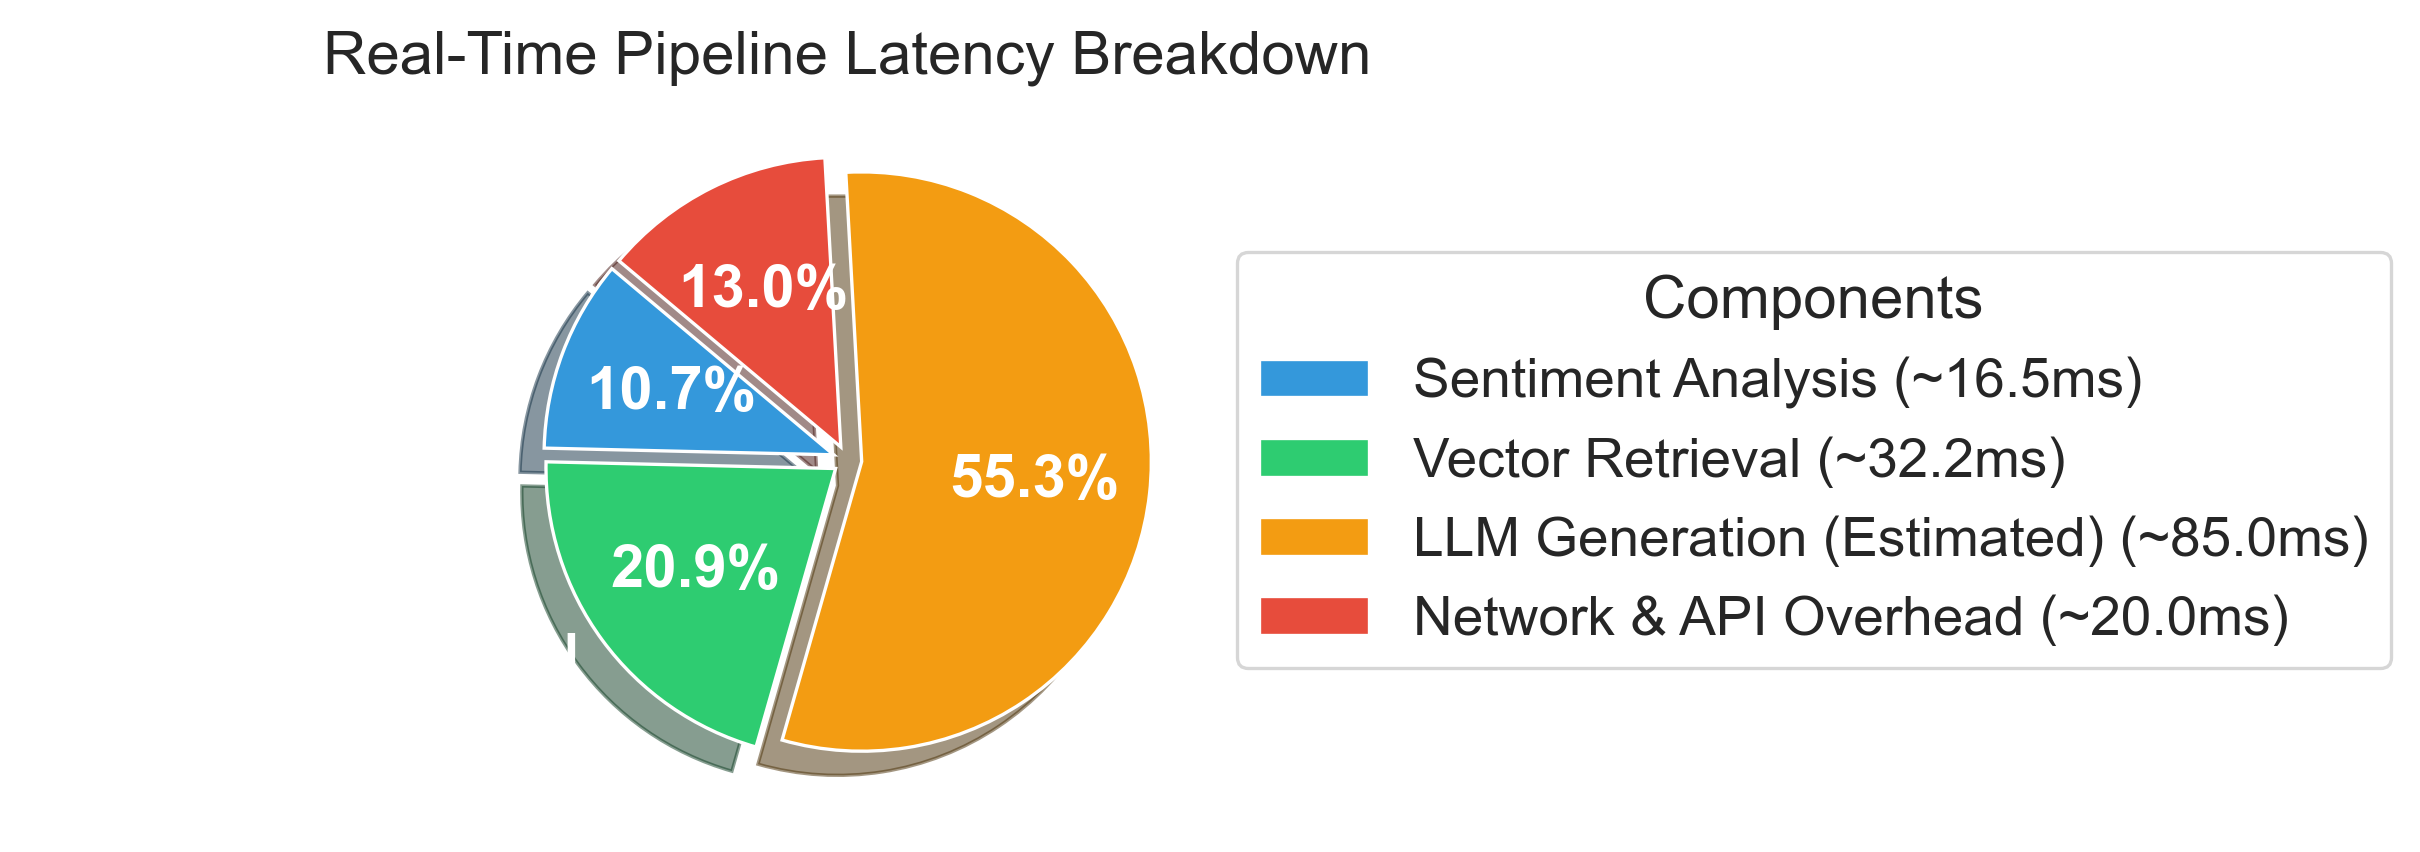

In [5]:
components = ['Sentiment Analysis', 'Vector Retrieval', 'LLM Generation (Estimated)', 'Network & API Overhead']
times = [16.51, 32.18, 85.00, 20.00]

fig, ax = plt.subplots(figsize=(8, 8))
colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c']
explode = (0.05, 0.05, 0.05, 0.05)

wedges, texts, autotexts = ax.pie(times, explode=explode, labels=components, colors=colors, 
                                  autopct='%1.1f%%', shadow=True, startangle=140,
                                  textprops=dict(color="w", fontweight='bold'))

ax.legend(wedges, [f"{c} (~{t:.1f}ms)" for c, t in zip(components, times)],
          title="Components",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))

ax.set_title('Real-Time Pipeline Latency Breakdown')

plt.tight_layout()
plt.savefig('latency_breakdown.pdf', bbox_inches='tight')
plt.show()